# DỰ ÁN PHÂN TÍCH TOÀN DIỆN: CHẤT LƯỢNG RƯỢU VANG ĐỎ (RED WINE QUALITY)
## BÁO CÁO THỰC THI 4 GIAI ĐOẠN (STAGES 1 - 4)
- **Tập dữ liệu:** `winequality-red.csv` (Cortez et al., 2009 - UCI Machine Learning Repository)
- **Nội dung thực hiện:**
  - **Giai đoạn 1:** Thu thập, cấu trúc trường, rà soát kiểu dữ liệu, đánh giá tỷ lệ missing values & tính toàn vẹn.
  - **Giai đoạn 2:** Tiền xử lý dữ liệu, kiểm định ngoại lệ (IQR), khử lặp (deduplication), Winsorization, RobustScaler & Feature Engineering.
  - **Giai đoạn 3:** Kiểm định giả thuyết thống kê (t-test, ANOVA, Pearson correlation), trực quan hóa đa biến & diễn giải chuyên sâu (Deep Insight).
  - **Giai đoạn 4:** Đánh giá tác động chuyên môn & kinh doanh, đề xuất giải pháp ứng dụng thực tế, chỉ ra hạn chế & hướng mở rộng.


In [1]:
# 1. Cài đặt môi trường và nạp các thư viện khoa học dữ liệu
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import RobustScaler, StandardScaler
import warnings
warnings.filterwarnings('ignore')

# Thiết lập phong cách trực quan hóa
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
print("Thư viện đã được nạp thành công!")


Thư viện đã được nạp thành công!


---
# GIAI ĐOẠN 1: THU THẬP VÀ ĐÁNH GIÁ DỮ LIỆU BAN ĐẦU
### 1.1. Đọc dữ liệu và rà soát cấu trúc ban đầu

In [2]:
df_raw = pd.read_csv('winequality-red.csv')
print(f"Kích thước tập dữ liệu gốc (Shape): {df_raw.shape[0]} dòng, {df_raw.shape[1]} thuộc tính.")
df_raw.head()


Kích thước tập dữ liệu gốc (Shape): 1599 dòng, 12 thuộc tính.


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


### 1.2. Rà soát kiểu dữ liệu và tỷ lệ khuyết thiếu (Missing Values)

In [3]:
audit_table = pd.DataFrame({
    'Kiểu Dtype': df_raw.dtypes,
    'Số bản ghi hợp lệ': df_raw.count(),
    'Số lượng thiếu (NaN)': df_raw.isnull().sum(),
    'Tỷ lệ thiếu (%)': (df_raw.isnull().sum() / len(df_raw)) * 100,
    'Số giá trị duy nhất (Unique)': df_raw.nunique()
})
audit_table


,Kiểu Dtype,Số bản ghi hợp lệ,Số lượng thiếu (NaN),Tỷ lệ thiếu (%),Số giá trị duy nhất (Unique)
fixed acidity,float64,1599,0,0.0,96
volatile acidity,float64,1599,0,0.0,143
citric acid,float64,1599,0,0.0,80
residual sugar,float64,1599,0,0.0,91
chlorides,float64,1599,0,0.0,153
free sulfur dioxide,float64,1599,0,0.0,60
total sulfur dioxide,float64,1599,0,0.0,144
density,float64,1599,0,0.0,436
pH,float64,1599,0,0.0,89
sulphates,float64,1599,0,0.0,96


### 1.3. Thống kê mô tả tổng quan (Descriptive Statistics)

In [4]:
summary_desc = df_raw.describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
summary_desc['IQR'] = summary_desc['75%'] - summary_desc['25%']
summary_desc


,count,mean,std,min,25%,50%,75%,max,IQR
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000,2.100000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000,0.250000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000,0.330000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000,0.700000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100,0.020000
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000,14.000000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000,40.000000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369,0.002235
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000,0.190000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000,0.180000


---
# GIAI ĐOẠN 2: TIỀN XỬ LÝ VÀ LÀM SẠCH DỮ LIỆU
### 2.1. Phát hiện và xử lý dữ liệu trùng lặp (Duplicate Records)

In [5]:
n_dup = df_raw.duplicated().sum()
pct_dup = (n_dup / len(df_raw)) * 100
print(f"Số lượng bản ghi trùng lặp: {n_dup} dòng ({pct_dup:.2f}%)")

# Loại bỏ trùng lặp
df_clean = df_raw.drop_duplicates(keep='first').copy()
print(f"Kích thước sau khi khử trùng lặp: {df_clean.shape[0]} dòng, {df_clean.shape[1]} cột")


Số lượng bản ghi trùng lặp: 240 dòng (15.01%)
Kích thước sau khi khử trùng lặp: 1359 dòng, 12 cột


### 2.2. Nhận diện và Định lượng ngoại lệ (Outliers) qua phương pháp IQR

In [6]:
outlier_summary = []
for col in df_clean.columns:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    cnt = ((df_clean[col] < low) | (df_clean[col] > high)).sum()
    outlier_summary.append({
        'Thuộc tính': col, 'Q1': round(q1, 3), 'Median': round(df_clean[col].median(), 3),
        'Q3': round(q3, 3), 'IQR': round(iqr, 3), 'Ngưỡng dưới': round(low, 3),
        'Ngưỡng trên': round(high, 3), 'Số Outlier': cnt, 'Tỷ lệ Outlier (%)': round(cnt / len(df_clean) * 100, 2)
    })
pd.DataFrame(outlier_summary)


,Thuộc tính,Q1,Median,Q3,IQR,Ngưỡng dưới,Ngưỡng trên,Số Outlier,Tỷ lệ Outlier (%)
0,fixed acidity,7.100,7.900,9.200,2.100,3.950,12.350,41,3.02
1,volatile acidity,0.390,0.520,0.640,0.250,0.015,1.015,19,1.40
2,citric acid,0.090,0.260,0.430,0.340,-0.420,0.940,1,0.07
3,residual sugar,1.900,2.200,2.600,0.700,0.850,3.650,126,9.27
4,chlorides,0.070,0.079,0.091,0.021,0.039,0.122,87,6.40
5,free sulfur dioxide,7.000,14.000,21.000,14.000,-14.000,42.000,26,1.91
6,total sulfur dioxide,22.000,38.000,63.000,41.000,-39.500,124.500,45,3.31
7,density,0.996,0.997,0.998,0.002,0.992,1.001,35,2.58
8,pH,3.210,3.310,3.400,0.190,2.925,3.685,28,2.06
9,sulphates,0.550,0.620,0.730,0.180,0.280,1.000,55,4.05


### 2.3. Áp dụng kỹ thuật Winsorization và Chuẩn hóa RobustScaler
- **Lý do không xóa bỏ Outlier:** Biến thiên đường dư, muối khoáng là đặc tính tự nhiên của rượu đặc biệt (rượu ngọt dessert wine, đất ven biển). Capping tại $1.5 \times IQR$ giúp kiểm soát biên cực đoan mà không mất cỡ mẫu.
- **Lý do dùng RobustScaler:** Tránh bị méo bởi phân phối lệch phải (Right-skewed).

In [7]:
# 1. Capping bằng Winsorization
features = [c for c in df_clean.columns if c != 'quality']
for col in features:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    df_clean[col] = np.clip(df_clean[col], q1 - 1.5 * iqr, q3 + 1.5 * iqr)

# 2. Tạo nhãn nhị phân cân bằng (0: Quality < 6, 1: Quality >= 6)
df_clean['quality_binary'] = (df_clean['quality'] >= 6).astype(int)

# 3. Chuẩn hóa đặc trưng bằng RobustScaler
scaler = RobustScaler()
scaled_vals = scaler.fit_transform(df_clean[features])
scaled_df = pd.DataFrame(scaled_vals, columns=[f'{c}_scaled' for c in features], index=df_clean.index)

# Ghép bảng dữ liệu sạch hoàn chỉnh
df_processed = pd.concat([df_clean, scaled_df], axis=1)
df_processed.to_csv('winequality-red-cleaned.csv', index=False)
print("Đã lưu tập dữ liệu sạch vào 'winequality-red-cleaned.csv'. Shape:", df_processed.shape)


Đã lưu tập dữ liệu sạch vào 'winequality-red-cleaned.csv'. Shape: (1359, 24)


---
# GIAI ĐOẠN 3: PHÂN TÍCH VÀ TRỰC QUAN HÓA DỮ LIỆU

### 3.1. Kiểm định các Giả thuyết Thống kê (Hypothesis Testing)
- **H1:** Nồng độ cồn (`alcohol`) tỉ lệ thuận với chất lượng rượu (`quality`).
- **H2:** Axit dễ bay hơi (`volatile acidity`) tỉ lệ nghịch với chất lượng rượu.
- **H3:** Độ ngọt (`residual sugar`) quyết định chất lượng vang đỏ.
- **H4:** Hàm lượng sunfat (`sulphates`) có tác động tích cực đến phẩm chất rượu.

In [8]:
# 1. Kiểm định H1 (Alcohol)
r1, p1 = stats.pearsonr(df_processed['alcohol'], df_processed['quality'])
low_alc = df_processed[df_processed['quality_binary'] == 0]['alcohol']
high_alc = df_processed[df_processed['quality_binary'] == 1]['alcohol']
t1, pt1 = stats.ttest_ind(high_alc, low_alc)
anova_groups = [df_processed[df_processed['quality'] == q]['alcohol'] for q in sorted(df_processed['quality'].unique())]
f1, p_anova1 = stats.f_oneway(*anova_groups)

print(f"[Kiểm định H1 - Alcohol]:")
print(f"  - Hệ số tương quan Pearson: r = {r1:.4f} (p-value = {p1:.3e})")
print(f"  - Two-sample t-test: t = {t1:.4f} (p-value = {pt1:.3e}) | Mean Kém/TB={low_alc.mean():.2f}%, Mean Ngon={high_alc.mean():.2f}%")
print(f"  - One-way ANOVA F = {f1:.4f} (p-value = {p_anova1:.3e}) => Chấp nhận H1!\n")

# 2. Kiểm định H2 (Volatile Acidity)
r2, p2 = stats.pearsonr(df_processed['volatile acidity'], df_processed['quality'])
low_va = df_processed[df_processed['quality_binary'] == 0]['volatile acidity']
high_va = df_processed[df_processed['quality_binary'] == 1]['volatile acidity']
t2, pt2 = stats.ttest_ind(high_va, low_va)
print(f"[Kiểm định H2 - Volatile Acidity]:")
print(f"  - Hệ số tương quan Pearson: r = {r2:.4f} (p-value = {p2:.3e})")
print(f"  - Two-sample t-test: t = {t2:.4f} (p-value = {pt2:.3e}) | Mean Kém/TB={low_va.mean():.2f}, Mean Ngon={high_va.mean():.2f}")
print(f"  => Chấp nhận H2! Mùi giấm làm hỏng phẩm chất rượu.\n")

# 3. Kiểm định H3 (Residual Sugar)
r3, p3 = stats.pearsonr(df_processed['residual sugar'], df_processed['quality'])
low_rs = df_processed[df_processed['quality_binary'] == 0]['residual sugar']
high_rs = df_processed[df_processed['quality_binary'] == 1]['residual sugar']
t3, pt3 = stats.ttest_ind(high_rs, low_rs)
print(f"[Kiểm định H3 - Residual Sugar]:")
print(f"  - Hệ số tương quan Pearson: r = {r3:.4f} (p-value = {p3:.4f} > 0.05)")
print(f"  - Two-sample t-test: t = {t3:.4f} (p-value = {pt3:.4f} > 0.05)")
print(f"  => Bác bỏ H3! Lượng đường dư không có tương quan tuyến tính với độ ngon vang đỏ.\n")

# 4. Kiểm định H4 (Sulphates)
r4, p4 = stats.pearsonr(df_processed['sulphates'], df_processed['quality'])
low_sul = df_processed[df_processed['quality_binary'] == 0]['sulphates']
high_sul = df_processed[df_processed['quality_binary'] == 1]['sulphates']
t4, pt4 = stats.ttest_ind(high_sul, low_sul)
print(f"[Kiểm định H4 - Sulphates]:")
print(f"  - Hệ số tương quan Pearson: r = {r4:.4f} (p-value = {p4:.3e})")
print(f"  - Two-sample t-test: t = {t4:.4f} (p-value = {pt4:.3e})")
print(f"  => Chấp nhận H4! Sunfat bảo vệ cấu trúc vang chống oxy hóa.\n")


[Kiểm định H1 - Alcohol]:
  - Hệ số tương quan Pearson: r = 0.4827 (p-value = 3.028e-80)
  - Two-sample t-test: t = 18.5473 (p-value = 1.268e-68) | Mean Kém/TB=9.92%, Mean Ngon=10.88%
  - One-way ANOVA F = 105.0371 (p-value = 8.594e-94) => Chấp nhận H1!

[Kiểm định H2 - Volatile Acidity]:
  - Hệ số tương quan Pearson: r = -0.3921 (p-value = 3.490e-51)
  - Two-sample t-test: t = -12.8034 (p-value = 1.627e-35) | Mean Kém/TB=0.59, Mean Ngon=0.47
  => Chấp nhận H2! Mùi giấm làm hỏng phẩm chất rượu.

[Kiểm định H3 - Residual Sugar]:
  - Hệ số tương quan Pearson: r = 0.0191 (p-value = 0.4814 > 0.05)
  - Two-sample t-test: t = -0.1902 (p-value = 0.8492 > 0.05)
  => Bác bỏ H3! Lượng đường dư không có tương quan tuyến tính với độ ngon vang đỏ.

[Kiểm định H4 - Sulphates]:
  - Hệ số tương quan Pearson: r = 0.3306 (p-value = 4.994e-36)
  - Two-sample t-test: t = 10.8686 (p-value = 1.927e-26)
  => Chấp nhận H4! Sunfat bảo vệ cấu trúc vang chống oxy hóa.



### 3.2. Trực quan hóa có mục tiêu & Diễn giải chuyên sâu (Deep Insight)

#### Biểu đồ 1: Ma trận nhiệt tương quan Pearson (Heatmap)
- **Mục tiêu:** Xác định toàn bộ mối quan hệ cặp giữa 11 chỉ số hóa lý với điểm chất lượng.

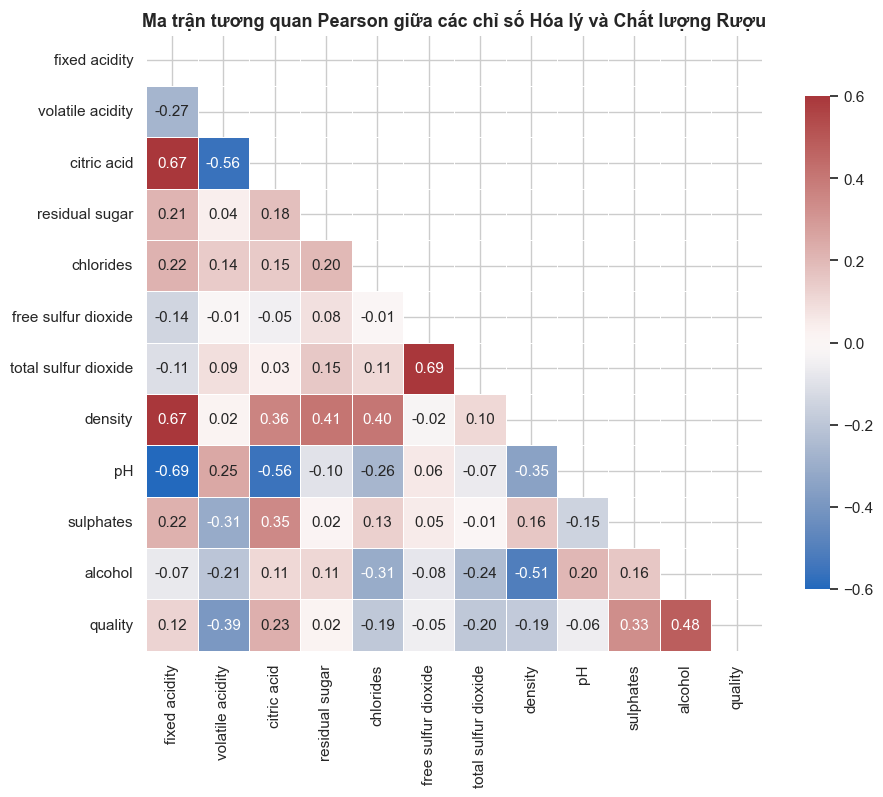

In [9]:
raw_cols = ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
            'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
            'pH', 'sulphates', 'alcohol', 'quality']

plt.figure(figsize=(11, 8))
mask = np.triu(np.ones_like(df_processed[raw_cols].corr(), dtype=bool))
sns.heatmap(df_processed[raw_cols].corr(), mask=mask, cmap='vlag', vmin=-0.6, vmax=0.6,
            annot=True, fmt='.2f', square=True, linewidths=.5, cbar_kws={'shrink': .8})
plt.title('Ma trận tương quan Pearson giữa các chỉ số Hóa lý và Chất lượng Rượu', fontsize=13, fontweight='bold')
plt.show()


**Deep Insight từ Heatmap:**
- **Nhóm thúc đẩy điểm số:** `alcohol` (+0.48), `sulphates` (+0.33), `citric acid` (+0.23).
- **Nhóm kéo tụt điểm số:** `volatile acidity` (-0.39), `total sulfur dioxide` (-0.18), `density` (-0.18).
- **Hiện tượng đa cộng tuyến:** `fixed acidity` tỉ lệ nghịch mạnh với `pH` (-0.68) và tỉ lệ thuận với `density` (+0.67). Khi ứng dụng mô hình tuyến tính cần thận trọng với chỉ số VIF.

#### Biểu đồ 2: Phân phối Violin & Boxplot cho Alcohol và Volatile Acidity
- **Mục tiêu:** Quan sát sự biến chuyển phân phối xác suất qua từng thang điểm từ 3 đến 8.

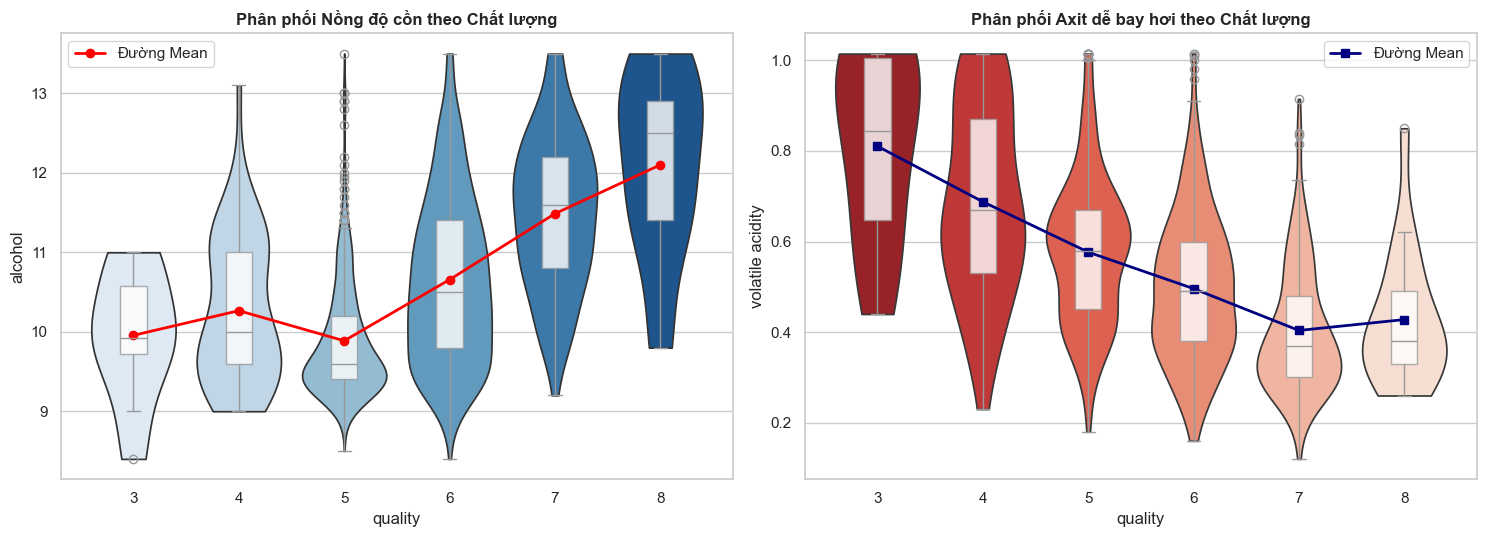

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Nồng độ cồn
sns.violinplot(x='quality', y='alcohol', data=df_processed, palette='Blues', inner=None, ax=axes[0], cut=0)
sns.boxplot(x='quality', y='alcohol', data=df_processed, width=0.25, ax=axes[0], color='white', boxprops=dict(alpha=0.8))
alc_m = df_processed.groupby('quality')['alcohol'].mean()
axes[0].plot(range(len(alc_m)), alc_m.values, marker='o', color='red', linewidth=2, label='Đường Mean')
axes[0].set_title('Phân phối Nồng độ cồn theo Chất lượng', fontweight='bold')
axes[0].legend()

# Axit dễ bay hơi
sns.violinplot(x='quality', y='volatile acidity', data=df_processed, palette='Reds_r', inner=None, ax=axes[1], cut=0)
sns.boxplot(x='quality', y='volatile acidity', data=df_processed, width=0.25, ax=axes[1], color='white', boxprops=dict(alpha=0.8))
va_m = df_processed.groupby('quality')['volatile acidity'].mean()
axes[1].plot(range(len(va_m)), va_m.values, marker='s', color='navy', linewidth=2, label='Đường Mean')
axes[1].set_title('Phân phối Axit dễ bay hơi theo Chất lượng', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()


**Deep Insight từ Violin-Boxplot:**
- Tồn tại **ngưỡng chuyển tiếp chất lượng (Quality Inflection Point)** tại điểm 6: Các dòng rượu đạt điểm 7-8 có đường trung bình nồng độ cồn vượt trội ($>11.5\%$) và kiểm soát axit axetic dưới $0.4\,g/dm^3$. Ở phân khúc điểm 3-5, nồng độ cồn thấp quanh mức $9.8\% - 10\%$, axit axetic thường xuyên vượt $0.6\,g/dm^3$.

#### Biểu đồ 3: Biểu đồ phân tán (Scatter Plot) giữa Axit bay hơi và Axit Citric
- **Mục tiêu:** Nhận diện vùng phân ranh chất lượng giữa vị chua hỏng (mùi giấm) và vị tươi mát (cam quýt).

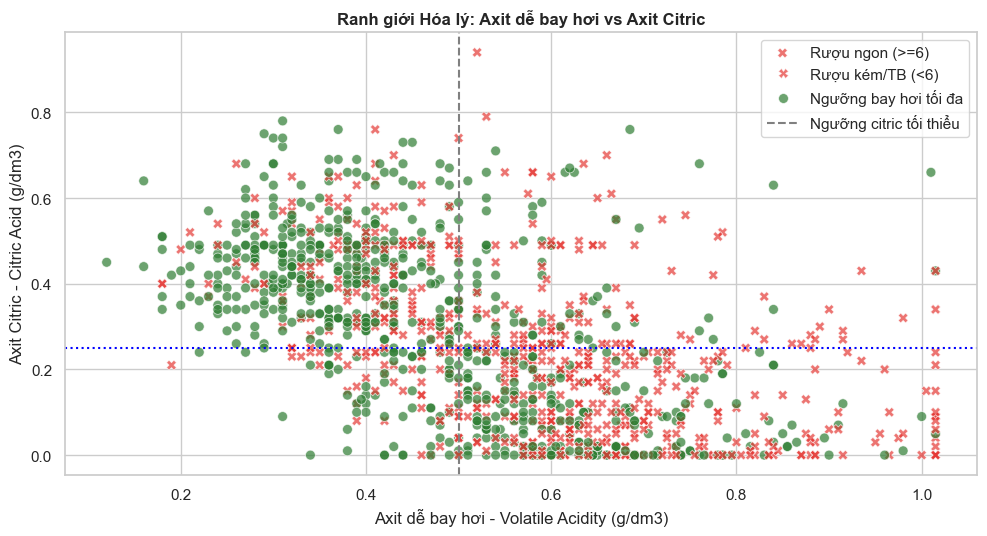

In [11]:
plt.figure(figsize=(10, 5.5))
sns.scatterplot(
    x='volatile acidity', y='citric acid',
    hue='quality_binary', palette={0: '#E53935', 1: '#2E7D32'},
    style='quality_binary', markers=['X', 'o'],
    data=df_processed, alpha=0.7, s=50
)
plt.axvline(0.5, color='gray', linestyle='--', label='Ngưỡng cảnh báo Axit bay hơi (0.5 g/dm3)')
plt.axhline(0.25, color='blue', linestyle=':', label='Ngưỡng chuẩn Axit Citric (0.25 g/dm3)')
plt.title('Ranh giới Hóa lý: Axit dễ bay hơi vs Axit Citric', fontweight='bold')
plt.xlabel('Axit dễ bay hơi - Volatile Acidity (g/dm3)')
plt.ylabel('Axit Citric - Citric Acid (g/dm3)')
plt.legend(labels=['Rượu ngon (>=6)', 'Rượu kém/TB (<6)', 'Ngưỡng bay hơi tối đa', 'Ngưỡng citric tối thiểu'])
plt.tight_layout()
plt.show()


#### Biểu đồ 4: So sánh hồ sơ hóa lý chuẩn hóa giữa Vang phổ thông và Vang thượng hạng
- **Mục tiêu:** Xây dựng chân dung kỹ thuật (Technical DNA) của một chai rượu cao cấp.

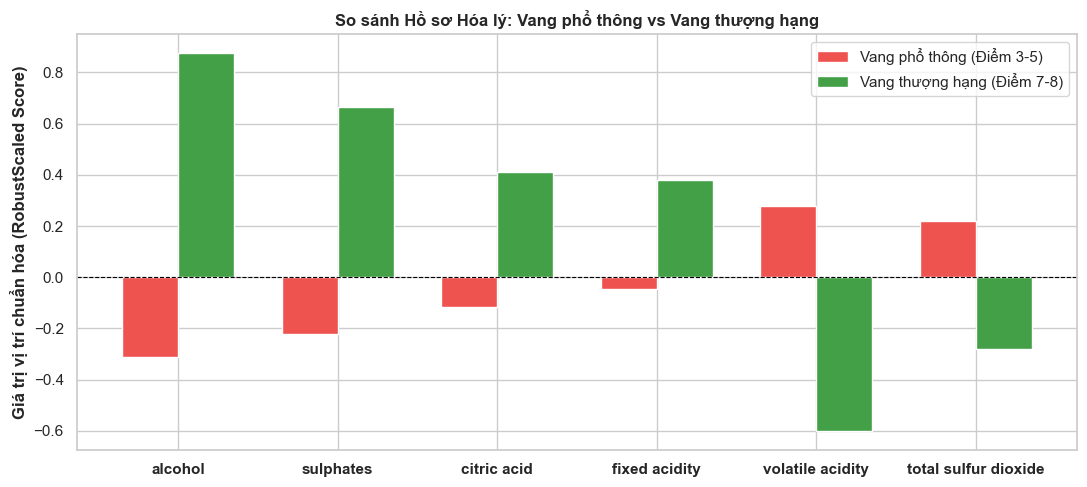

In [12]:
compare_cols = ['alcohol', 'sulphates', 'citric acid', 'fixed acidity', 'volatile acidity', 'total sulfur dioxide']
low_prof = df_processed[df_processed['quality'] <= 5][[f'{c}_scaled' for c in compare_cols]].median()
high_prof = df_processed[df_processed['quality'] >= 7][[f'{c}_scaled' for c in compare_cols]].median()

comp_df = pd.DataFrame({
    'Chỉ số': compare_cols,
    'Vang phổ thông (Điểm 3-5)': low_prof.values,
    'Vang thượng hạng (Điểm 7-8)': high_prof.values
})

fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(compare_cols))
w = 0.35
ax.bar(x - w/2, comp_df['Vang phổ thông (Điểm 3-5)'], w, label='Vang phổ thông (Điểm 3-5)', color='#EF5350')
ax.bar(x + w/2, comp_df['Vang thượng hạng (Điểm 7-8)'], w, label='Vang thượng hạng (Điểm 7-8)', color='#43A047')
ax.set_ylabel('Giá trị vị trí chuẩn hóa (RobustScaled Score)', fontweight='bold')
ax.set_title('So sánh Hồ sơ Hóa lý: Vang phổ thông vs Vang thượng hạng', fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(compare_cols, fontweight='bold')
ax.axhline(0, color='black', linestyle='--', linewidth=0.8)
ax.legend()
plt.tight_layout()
plt.show()


---
# GIAI ĐOẠN 4: ĐÁNH GIÁ TÁC ĐỘNG VÀ KHUYẾN NGHỊ

### 4.1. Tóm tắt các phát hiện chuyên môn và kinh doanh nổi bật
1. **Bộ ba trụ cột tạo nên rượu vang xuất sắc:** Nồng độ cồn cao ($11.5\% - 12.5\%$), hàm lượng axit bay hơi thấp ($< 0.45\,g/dm^3$), và được bảo vệ bởi sunfat dồi dào ($> 0.65\,g/dm^3$).
2. **Kẻ thù số 1 là axit axetic:** Axit bay hơi làm sụt giảm nghiêm trọng điểm cảm quan nếm thử ($r = -0.392$).
3. **Phá vỡ giả định về độ ngọt:** Lượng đường dư (`residual sugar`) không có tương quan tuyến tính với điểm chất lượng ($r = +0.019, p = 0.481$). Đối với vang đỏ khô, người sành rượu đánh giá cao cấu trúc tannin, độ đầm và tính cân bằng hơn là vị ngọt.

---

### 4.2. Đề xuất giải pháp ứng dụng thực tế
1. **Kiểm soát quy trình sản xuất (Operations & Brewing):**
   - Lắp đặt hệ thống cảm biến đo đạc tự động chỉ số `volatile acidity` trong thùng ủ. Nếu chỉ số vượt ngưỡng $0.50\,g/dm^3$, lập tức can thiệp bằng điều hòa nhiệt độ và bổ sung liều lượng $SO_2$ hợp chuẩn để triệt tiêu vi khuẩn lên men giấm.
   - Thu hoạch nho đạt độ chín đường tối ưu để tiềm năng chuyển hóa cồn tự nhiên đạt trên $11.5\%$.
2. **Phân loại chất lượng tự động bằng Machine Learning (AI-powered QA):**
   - Xây dựng mô hình phân loại (Random Forest / XGBoost) dựa trên 11 chỉ số phòng lab để dự đoán trước tỷ lệ đạt chuẩn Premium/Reserve.
   - Giúp nhà sản xuất chủ động phân luồng dán nhãn sản phẩm, tiết kiệm chi phí thuê hội đồng chuyên gia nếm thử thủ công.

---

### 4.3. Giới hạn dữ liệu và Hướng mở rộng tương lai
1. **Giới hạn hiện tại:**
   - Dữ liệu thu thập từ một vùng địa lý duy nhất (Vinho Verde, Bồ Đào Nha).
   - Thiếu các biến số ngoại cảnh quan trọng: Giống nho (Grape variety), Năm thu hoạch mùa vụ (Vintage), Thời gian ủ thùng sồi (Oak aging).
   - Mất cân bằng lớp: $82.5\%$ mẫu tập trung ở điểm 5 và 6; các điểm 3 và 8 cực hiếm.
2. **Hướng mở rộng:**
   - Thu thập thêm dữ liệu khí tượng mùa vụ (lượng mưa, số giờ nắng).
   - Ứng dụng kỹ thuật giải thích mô hình **SHAP (SHapley Additive exPlanations)** để tư vấn tinh chỉnh công thức cho từng mẻ rượu cụ thể.
